<a href="https://colab.research.google.com/github/codewithajinkya-dev/codewithajinkya-dev/blob/main/Google-Data-Analysis-Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [82]:
!pip install matplot lib pandas numpy seaborn plotly

In [83]:
!pip install pytrends

In [84]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pytrends.request import TrendReq

In [85]:
pytrends = TrendReq(hl='en-US', tz=360)
keyword ="Artificial intelligence"


Data Request


In [86]:
pytrends.build_payload(
    [keyword],
    cat=0,
    timeframe='today 12-m',
    geo='',
    gprop=''
)

In [95]:
#country wize request
region_data = pytrends.interest_by_region()
region_data =region_data.sort_values(by=keyword,ascending=False).head(15)

/tmp/ipykernel_4325/2690959418.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




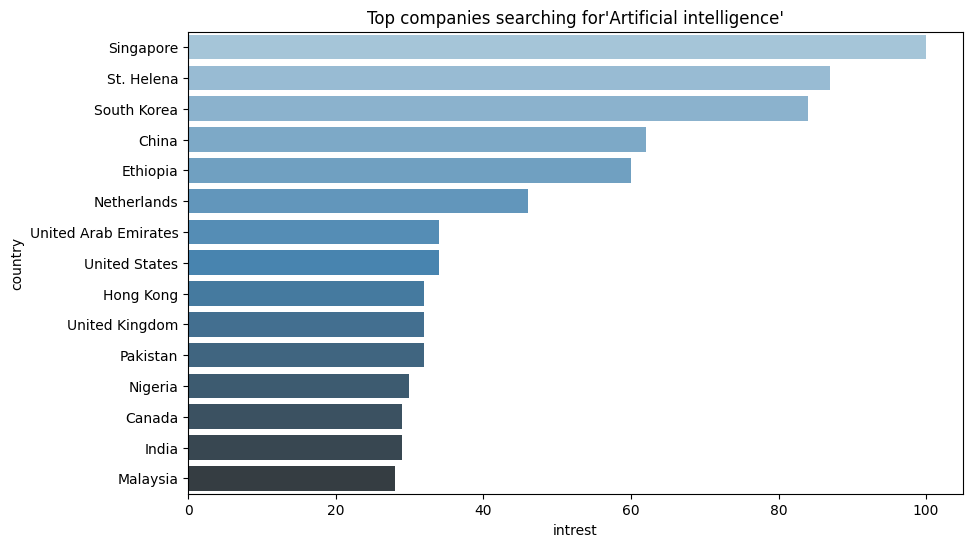

In [96]:
plt.figure(figsize=(10,6))
sns.barplot(x=region_data[keyword],y=region_data.index,palette="Blues_d")
plt.title(f"Top companies searching for'{keyword}'")
plt.xlabel("intrest")
plt.ylabel("country")
plt.show()

In [113]:
region_data=region_data.reset_index(drop=True)
fig = px.choropleth(
    region_data,
    locations='geoName',
    locationmode='country names',
    color=keyword,
    title="Search Interest for Artificial Intelligence by Country",
    color_continuous_scale='Blues'
)

fig.show()

In [99]:
#time wise interest
time_df = pytrends.interest_over_time()


/usr/local/lib/python3.13/dist-packages/pytrends/request.py:260: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



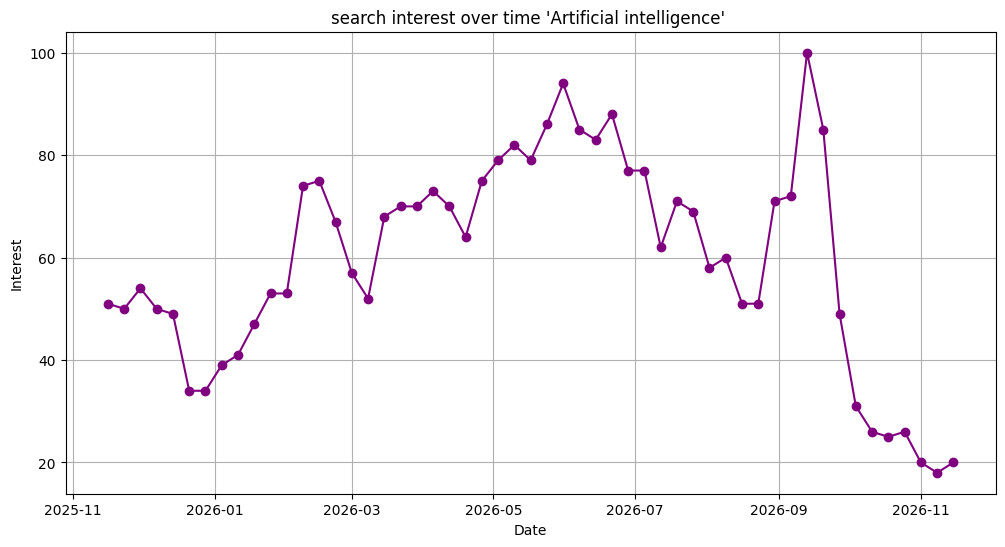

In [105]:
plt.figure(figsize=(12,6))
plt.plot(time_df.index,time_df[keyword],marker='o',color='purple')
plt.title(f"search interest over time '{keyword}' ")
plt.xlabel("Date")
plt.ylabel("Interest")
plt.grid(True)
plt.show()

In [101]:
#multiple keyword compare

kw_list=['cloud computing','data science','machine learning']
pytrends.build_payload(kw_list,
                       cat=0,
                       timeframe='today 12-m',
                       geo='',
                       gprop='')

/usr/local/lib/python3.13/dist-packages/pytrends/request.py:260: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



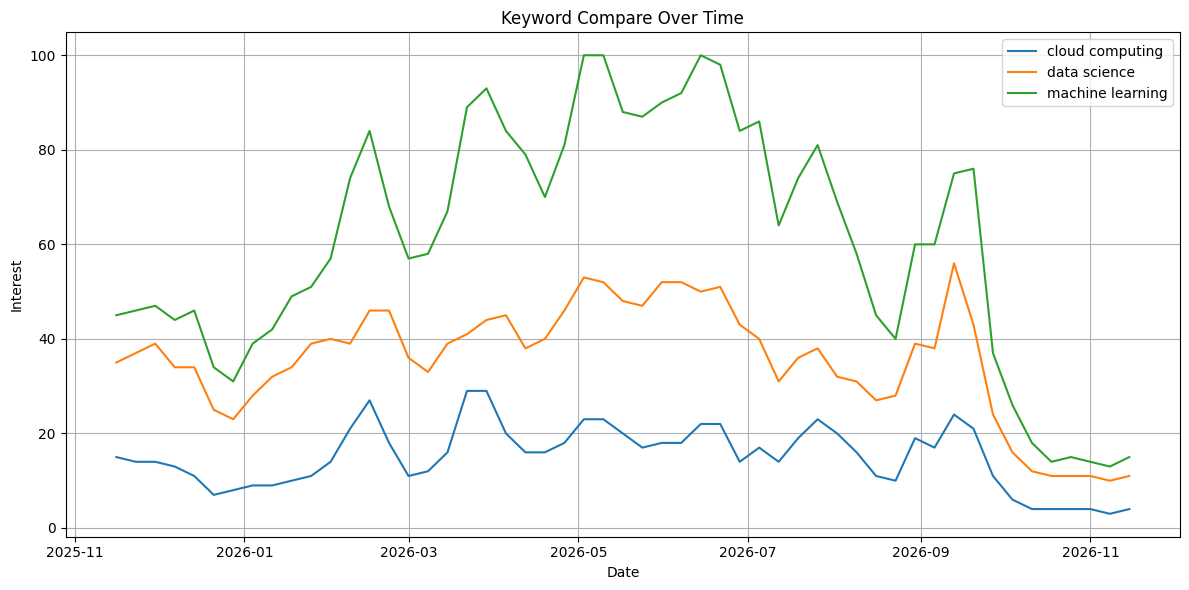

In [102]:
compare_df = pytrends.interest_over_time()

plt.figure(figsize=(12, 6))

for kw in kw_list:
    plt.plot(compare_df.index, compare_df[kw], label=kw)

plt.title("Keyword Compare Over Time")
plt.xlabel("Date")
plt.ylabel("Interest")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()